# Load data

In [1]:
import rpy2.robjects as robjects
from rpy2.robjects import numpy2ri
import numpy as np
import pickle

# --- Setup rpy2 ---
# This line is crucial to allow conversion between R and NumPy objects
numpy2ri.activate()

# Define file paths
rdata_path = 'FRED-MD data/fredmd_data.RData'
output_path = 'FRED-MD data/fredmd_data.pkl'

print(f"Attempting to load '{rdata_path}' using rpy2...")

try:
    # --- Use R to load the data, supplied from Cho ---
    # This command is sent to the R process to execute: load("fredmd_data.RData")
    robjects.r(f"load('{rdata_path}')")

    # --- Access the loaded R object ---
    # After loading, the 'fredmd_data' object exists in R's global environment.
    # We can access it by name.
    r_object = robjects.r['fredmd_data']

    print("Successfully accessed the 'fredmd_data' object from R.")

    # --- Convert the R object to a Python dictionary of NumPy arrays ---
    # We access each component of the R list using .rx2('component_name')
    # and convert it to a NumPy array.
    python_data = {
        'X': np.array(r_object.rx2('X')),
        'y': np.array(r_object.rx2('y')).flatten(), # .flatten() to ensure 1D
        'date': np.array(r_object.rx2('date')).flatten()
    }
    
    print("\nData converted to Python format successfully.")
    print("Shape of X:", python_data['X'].shape)
    print("Shape of y:", python_data['y'].shape)
    print("Number of dates:", len(python_data['date']))

    # --- Save to a Python-native format ---
    # This is highly recommended so you don't have to do this conversion again.
    with open(output_path, 'wb') as f:
        pickle.dump(python_data, f)
    

except Exception as e:
    print(f"\nAn error occurred: {e}")
    print("Please ensure that R is installed and that the rpy2 Python package is installed correctly.")

Attempting to load 'FRED-MD data/fredmd_data.RData' using rpy2...
Successfully accessed the 'fredmd_data' object from R.

Data converted to Python format successfully.
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773


In [2]:
import pickle
import numpy as np

# Define the path to your .pkl file
pkl_path = '/scratch/ga442/Weighted-ERM/FRED-MD data/fredmd_data.pkl'
pkl_path_local = 'FRED-MD data/fredmd_data.pkl'

# Open the file in binary read mode ('rb')
try:
    with open(pkl_path, 'rb') as f:
        # Load the data from the file
        loaded_data = pickle.load(f)
except FileNotFoundError:
    with open(pkl_path_local, 'rb') as f:
        # Load the data from the file
        loaded_data = pickle.load(f)


# Assign the data to your variables
X = loaded_data['X']
y = loaded_data['y']
date = loaded_data['date']
X_ = X.copy()
y_ = y.copy()
date_ = date.copy()

# --- Verification (Optional but good practice) ---
print("Data loaded successfully!")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")
print(f"Number of dates: {len(date)}")
print(f"First 5 dates: {date[:5]}")# Load the python

Data loaded successfully!
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773
First 5 dates: ['1960-01' '1960-02' '1960-03' '1960-04' '1960-05']


# WERM + full CV

In [77]:
from itertools import product
import jax.numpy as jnp
import WERM.estimators

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)
M_scorer = M

# Estimate sigma_hat
lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) # Match roughly the scale used in the lasso

L=4
delta_fraction = 1/10
Delta_n = lambda n_len: int(n_len * delta_fraction)

def f(X_train, y_train, param_tup):
    L_tilde, C_tilde = param_tup
    l1_reg_tilde = C_tilde * n * lambda_hat
    P_func = lambda beta: l1_reg_tilde * jnp.sum(jnp.abs(beta))

    return WERM.estimators.weighted_erm(X_train, y_train, M, L=L_tilde, Delta_n=Delta_n(n), gamma=0.0,
                        brute_force=False, P_func=P_func, return_gof=False)

# C_candidates = np.array([1e-1, 3, 5, 6, 6.5, 7, 7.5, 8, 8.5, 9])
# C_candidates = np.array([1e-1, 5, 6.5, 7, 7.5, 8, 8.5, 9])
# C_candidates = np.array([7, 7.5, 8, 8.5])
C_candidates = np.array([1e-1, 1, 3, 5, 7, 9])
# C_candidates = np.array([5])
L_candidates = np.arange(1, L + 1)
gamma_candidates = list(product(L_candidates, C_candidates))


num_folds = 2
best_L_tilde, best_chgpt_est = WERM.estimators.chgpt_k_fold_cv(
    f=f,
    X=X,
    y=y,
    gamma_candidates=gamma_candidates,
    M_scorer=M_scorer,
    P_scorer=None,
    k=num_folds,
    n_jobs=1
)
print("Best (L, C): ", best_L_tilde)
print("Estimated changepoints (Full CV): ", best_chgpt_est)

Running 2-fold CV for 24 gamma candidates using 1 cores...


CV Progress:   0%|          | 0/24 [00:00<?, ?it/s]

\Delta: 9, n: 50, Lmin: 1, Lmax: 1


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

\Delta: 9, n: 50, Lmin: 1, Lmax: 1


... (140 outputs left out)

  Tested 386 valid positions
  Best 5 improvements: [(350, Array(0.00061258, dtype=float64), Array(325.76249816, dtype=float64)), (349, Array(0.00060286, dtype=float64), Array(325.76250788, dtype=float64)), (348, Array(0.00060193, dtype=float64), Array(325.76250881, dtype=float64)), (347, Array(0.00060001, dtype=float64), Array(325.76251074, dtype=float64)), (351, Array(0.00059092, dtype=float64), Array(325.76251982, dtype=float64))]
  Tested 273 valid positions
  Best 5 improvements: [(90, Array(1.67347467e-05, dtype=float64), Array(325.76248142, dtype=float64)), (94, Array(-1.14766917e-05, dtype=float64), Array(325.76250963, dtype=float64)), (95, Array(-2.36741919e-05, dtype=float64), Array(325.76252183, dtype=float64)), (89, Array(-4.75887614e-05, dtype=float64), Array(325.76254575, dtype=float64)), (64, Array(-4.98179292e-05, dtype=float64), Array(325.76254798, dtype=float64))]
  Tested 120 valid positions
  Best 5 improvements: [(188, Array(0.00393963, dtype=float64), Array(325.75

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  Tested 772 valid positions
  Best 5 improvements: [(724, Array(0.00019194, dtype=float64), Array(598.97212597, dtype=float64)), (723, Array(0.0001878, dtype=float64), Array(598.97213011, dtype=float64)), (725, Array(8.92696966e-05, dtype=float64), Array(598.97222864, dtype=float64)), (700, Array(6.30003582e-05, dtype=float64), Array(598.97225491, dtype=float64)), (714, Array(6.15537728e-05, dtype=float64), Array(598.97225636, dtype=float64))]

Applying local refinement...
Best (L, C):  (np.int64(2), np.float64(1.0))
Estimated changepoints (Full CV):  [724]


WERM chpt estimate:  [724]
Change point dates (ERM):  ['2020-05']
Done optimizing gof erm.


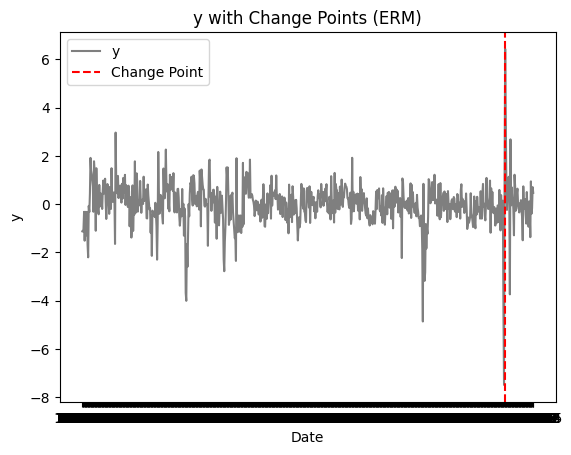

In [ ]:
cp = best_chgpt_est
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", cp)
# Print the dates associated with the change points
chgpt_dates_erm = date[cp]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

In [13]:
np.array([1e-1, 1, 3, 5, 7, 9]) * 773

array([  77.3,  773. , 2319. , 3865. , 5411. , 6957. ])

# WERM with exactly 3 change points

In [ ]:
from itertools import product
import jax.numpy as jnp
import WERM.estimators
  
n, p = X.shape
# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)
M_scorer = M

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)

# Absolute value loss
# M_scorer = lambda u, v: jnp.abs(u - v)

# Estimate sigma_hat
lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) # Match roughly the scale used in the lasso

L=4
delta_fraction = 1/10
Delta_n = lambda n_len: int(n_len * delta_fraction)

def f(X_train, y_train, param_tup):
    L_tilde, C_tilde = param_tup
    l1_reg_tilde = C_tilde * lambda_hat
    # l1_reg_tilde = C_tilde * n * lambda_hat
    P_func = lambda beta: l1_reg_tilde * jnp.sum(jnp.abs(beta))

    return WERM.estimators.weighted_erm(X_train, y_train, M, L=L_tilde, Delta_n=Delta_n(n), gamma=0.0,
                        brute_force=False, P_func=P_func, return_gof=False)

# C_candidates = np.array([1e-1, 1, 3, 5, 7, 9])
C_candidates = np.array([  77.3,  773. , 2319. , 3865. , 5411. , 6957. ]) # above multiplied by 773
L_candidates = np.arange(L, L + 1)
gamma_candidates = list(product(L_candidates, C_candidates))

num_folds = 2
best_L_tilde, best_chgpt_est = WERM.estimators.chgpt_k_fold_cv(
    f=f,
    X=X,
    y=y,
    gamma_candidates=gamma_candidates,
    M_scorer=M_scorer,
    P_scorer=None,
    k=num_folds,
    n_jobs=1
)
print("Best (L, C): ", best_L_tilde)
print("Estimated changepoints (Full CV): ", best_chgpt_est)

Running 2-fold CV for 6 gamma candidates using 1 cores...


CV Progress:   0%|          | 0/6 [00:00<?, ?it/s]

\Delta: 9, n: 50, Lmin: 4, Lmax: 4


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/220 [00:00<?, ?it/s]

  Tested 385 valid positions
  Best 5 improvements: [(48, Array(0.0054549, dtype=float64), Array(273.20200459, dtype=float64)), (47, Array(0.0054494, dtype=float64), Array(273.20201009, dtype=float64)), (49, Array(0.00544587, dtype=float64), Array(273.20201361, dtype=float64)), (40, Array(0.00538114, dtype=float64), Array(273.20207835, dtype=float64)), (43, Array(0.00537975, dtype=float64), Array(273.20207973, dtype=float64))]
  Tested 261 valid positions
  Best 5 improvements: [(385, Array(1.58738374e-06, dtype=float64), Array(273.202003, dtype=float64)), (384, Array(-2.33553992e-05, dtype=float64), Array(273.20202794, dtype=float64)), (380, Array(-0.00010117, dtype=float64), Array(273.20210576, dtype=float64)), (381, Array(-0.00011193, dtype=float64), Array(273.20211652, dtype=float64)), (382, Array(-0.00011319, dtype=float64), Array(273.20211778, dtype=float64))]
  Tested 184 valid positions
  Best 5 improvements: [(292, Array(-0.00174544, dtype=float64), Array(273.20374844, dtype=f

... (32 outputs left out)

  Tested 386 valid positions
  Best 5 improvements: [(350, Array(0.00042781, dtype=float64), Array(325.76312344, dtype=float64)), (349, Array(0.00042151, dtype=float64), Array(325.76312975, dtype=float64)), (348, Array(0.00042085, dtype=float64), Array(325.7631304, dtype=float64)), (347, Array(0.00041941, dtype=float64), Array(325.76313185, dtype=float64)), (351, Array(0.00041207, dtype=float64), Array(325.76313918, dtype=float64))]
  Tested 273 valid positions
  Best 5 improvements: [(90, Array(5.29579727e-05, dtype=float64), Array(325.76307048, dtype=float64)), (94, Array(3.37294416e-05, dtype=float64), Array(325.76308971, dtype=float64)), (95, Array(2.46974033e-05, dtype=float64), Array(325.76309874, dtype=float64)), (89, Array(1.58073817e-06, dtype=float64), Array(325.76312186, dtype=float64)), (64, Array(-2.26008041e-06, dtype=float64), Array(325.7631257, dtype=float64))]
  Tested 120 valid positions
  Best 5 improvements: [(177, Array(0.00142416, dtype=float64), Array(325.7616463

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4960 [00:00<?, ?it/s]

  Tested 772 valid positions
  Best 5 improvements: [(129, Array(0.00059044, dtype=float64), Array(598.97173283, dtype=float64)), (126, Array(0.00051696, dtype=float64), Array(598.9718063, dtype=float64)), (125, Array(0.00051612, dtype=float64), Array(598.97180715, dtype=float64)), (58, Array(0.00051593, dtype=float64), Array(598.97180734, dtype=float64)), (128, Array(0.00051209, dtype=float64), Array(598.97181118, dtype=float64))]
  Tested 619 valid positions
  Best 5 improvements: [(722, Array(0.0003401, dtype=float64), Array(598.97139273, dtype=float64)), (719, Array(0.00033536, dtype=float64), Array(598.97139746, dtype=float64)), (717, Array(0.00033445, dtype=float64), Array(598.97139837, dtype=float64)), (720, Array(0.00033382, dtype=float64), Array(598.97139901, dtype=float64)), (721, Array(0.00033364, dtype=float64), Array(598.97139918, dtype=float64))]
  Tested 492 valid positions
  Best 5 improvements: [(588, Array(0.00171236, dtype=float64), Array(598.96968037, dtype=float64)

WERM chpt estimate:  [129 588 722]
Change point dates (ERM):  ['1970-10' '2009-01' '2020-03']
Done optimizing gof erm.


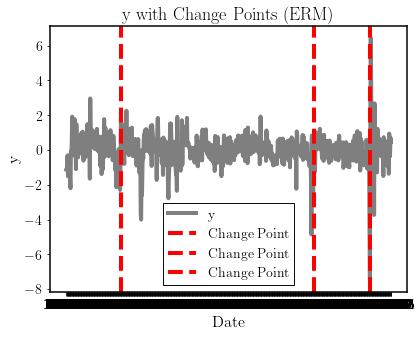

In [15]:
import matplotlib.pyplot as plt
cp = best_chgpt_est
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", cp)
# Print the dates associated with the change points
chgpt_dates_erm = date[cp]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

## Format the plot

Removing 110 matplotlib modules...
Successfully set backend to: pgf
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Error converting dates to datetime objects: time data '1960-01' does not match format '%Y-%m-%d'
Please ensure your 'date' array contains strings in a consistent format (e.g., 'YYYY-MM-DD').

Creating publication-ready change point plot...
Change point estimates (indices):  [129 692 772]
Change point dates:  [np.str_('1970-10'), np.str_('2017-09'), np.str_('2024-05')]
Plot saved as figures/FRED-MD-3-chgpt-sparse.pdf and figures/FRED-MD-3-chgpt-sparse.pgf


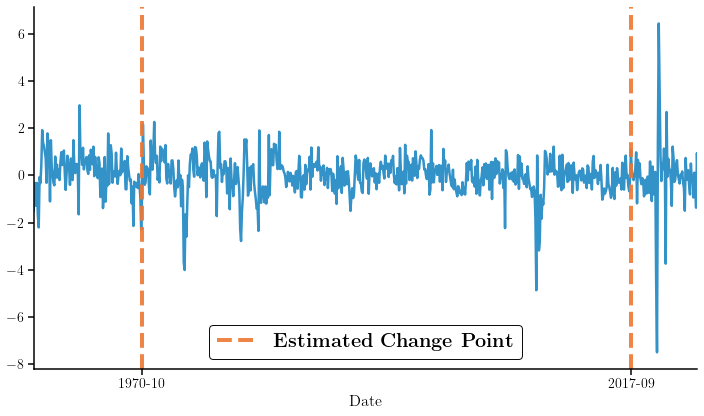

Change point plotting completed.


In [195]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import gc
import datetime # For date conversion
import os # For creating directories

# --- Matplotlib Cleanup and Backend Setting ---
# Close all existing figures first
try:
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib and set backend
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# --- Publication-Ready Matplotlib Parameters ---
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,    # Larger axis labels
    'axes.titlesize': 18,    # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 72,          # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# --- Color Palette ---
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']
PAL = TOL_VIBRANT
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- IMPORTANT: Convert date strings to datetime objects ---
try:
    if isinstance(date[0], (np.str_, str)):
        converted_dates = [datetime.datetime.strptime(str(d), '%Y-%m-%d').date() for d in date]
        date = converted_dates
    else:
        print("Date array already contains datetime objects or an unexpected type. Skipping conversion.")
except Exception as e:
    print(f"Error converting dates to datetime objects: {e}")
    print("Please ensure your 'date' array contains strings in a consistent format (e.g., 'YYYY-MM-DD').")


# --- Publication-Ready Change Point Plotting Function ---
def plot_changepoints_publication(dates, y_values, chgpt_indices, title_label=''):
    """
    Generates a publication-ready plot of a time series with overlaid change points.

    Args:
        dates (list or array-like): The dates corresponding to the time series.
                                    Expected to be datetime.date or datetime.datetime objects.
        y_values (list or array-like): The time series data.
        chgpt_indices (list or array-like): The estimated change point indices.
        title_label (str): An optional label to include in the plot title.
    """
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))

    chgpt_dates_erm = [dates[i] for i in chgpt_indices] # Dates at change points

    print("Change point estimates (indices): ", chgpt_indices)
    print("Change point dates: ", chgpt_dates_erm)

    # Plot the y values with the change points as vertical lines
    ax.plot(dates, y_values, 
            color=PAL[1], alpha=0.8, linewidth=2.5) # Using a color from the palette

    # Add vertical lines for change points
    for i, chgpt_date in enumerate(chgpt_dates_erm):
        # Only label the first change point to avoid duplicate legend entries
        label = r'\textbf{Estimated Change Point}' if i == 0 else ""
        ax.axvline(x=chgpt_date, color=PAL[0], linestyle='--',
                   linewidth=4, label=label, alpha=0.9) # Using another color from the palette

    # ax.set_title(r'\textbf{Time Series with Estimated Change Points}' + title_label, pad=15)
    ax.set_xlabel(r'Date')
    # ax.set_ylabel(r'\textbf{Value of} $\mathbf{y}$')

    # Cleaner axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # --- MODIFICATION: Set xticks only at change point dates ---
    ax.set_xticks(chgpt_dates_erm)
    # ax.set_xticklabels([d.strftime('%Y-%m-%d') for d in chgpt_dates_erm], rotation=30, ha='right')
    ax.set_xlim(dates[5], dates[-5])  # Set x limits to the full date range

    ax.legend(loc='best', frameon=True, edgecolor='black', framealpha=0.95, fancybox=True,
              fontsize=20)
    fig.tight_layout()

    return fig, ax

# --- Execute Plotting ---
print("\nCreating publication-ready change point plot...")
fig_chgpt, ax_chgpt = plot_changepoints_publication(date, y, cp, title_label=r' (ERM Method)')

# --- Save and Show Plot ---
filename_prefix = 'FRED-MD-3-chgpt-sparse'
os.makedirs('figures', exist_ok=True) # Ensure 'figures' directory exists

fig_chgpt.savefig(f'figures/{filename_prefix}.pdf', dpi=300, bbox_inches='tight')
fig_chgpt.savefig(f'figures/{filename_prefix}.pgf', dpi=300, bbox_inches='tight')
print(f"Plot saved as figures/{filename_prefix}.pdf and figures/{filename_prefix}.pgf")

plt.show(fig_chgpt)

print("Change point plotting completed.")

# Inspect Regression Vectors

Removing 110 matplotlib modules...
Successfully set backend to: pgf
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Using C_best: 5411.0 for regularization
Computed l1_reg_best: 598.9874600187192
Segment 1 - Mean: 0.0, Std: 0.0
Segment 1 - First 10 Coefficients Mean: 0.0, Std: 0.0
Segment 2 - Mean: 0.0, Std: 0.0
Segment 2 - First 10 Coefficients Mean: 0.0, Std: 0.0
Segment 3 - Mean: 0.0, Std: 0.0
Segment 3 - First 10 Coefficients Mean: 0.0, Std: 0.0
Segment 4 - Mean: 0.0, Std: 0.0
Segment 4 - First 10 Coefficients Mean: 0.0, Std: 0.0

Creating publication-ready regression coefficient plots...
Plot saved as figures/segment_regression_coefficients_all.pdf and figures/segment_regression_coefficients_all.pgf


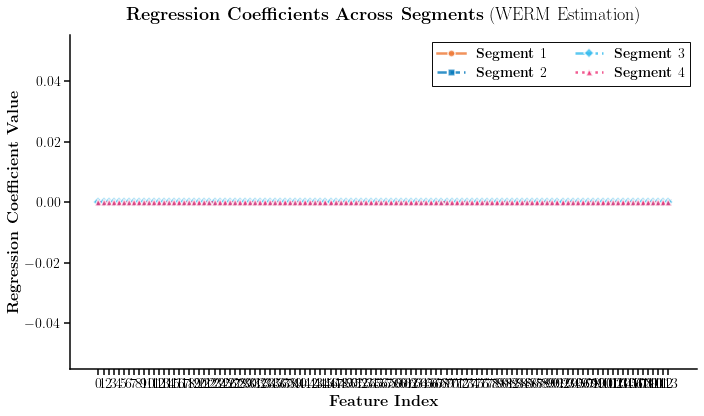

Plot saved as figures/adjacent_segment_coefficient_comparison.pdf and figures/adjacent_segment_coefficient_comparison.pgf


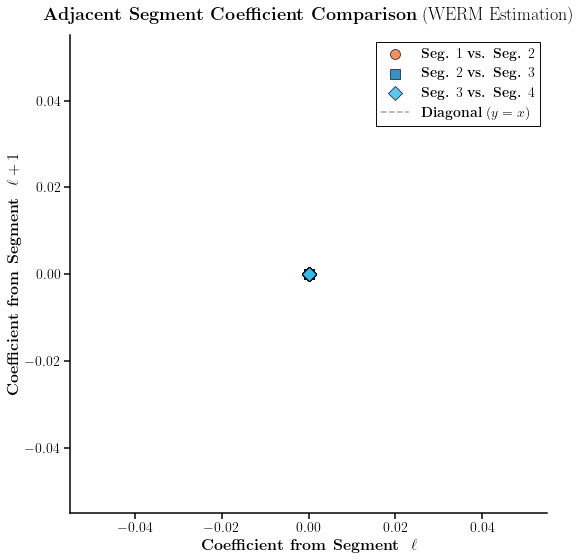


Creating individual plots for adjacent segment coefficient comparisons...
Plot saved as figures/segment_coeffs_seg1_vs_seg2.pdf and figures/segment_coeffs_seg1_vs_seg2.pgf


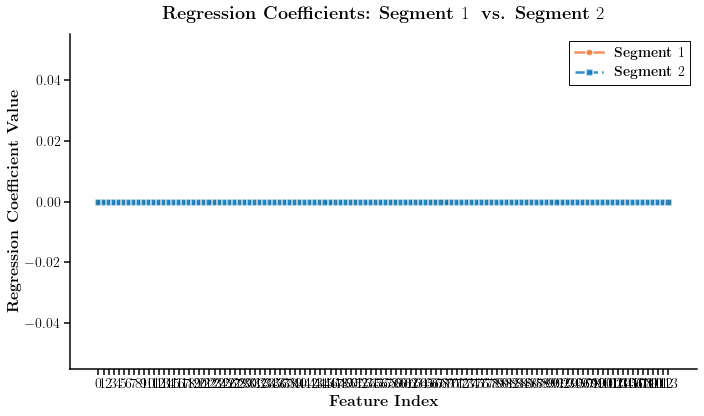

Plot saved as figures/segment_coeffs_seg2_vs_seg3.pdf and figures/segment_coeffs_seg2_vs_seg3.pgf


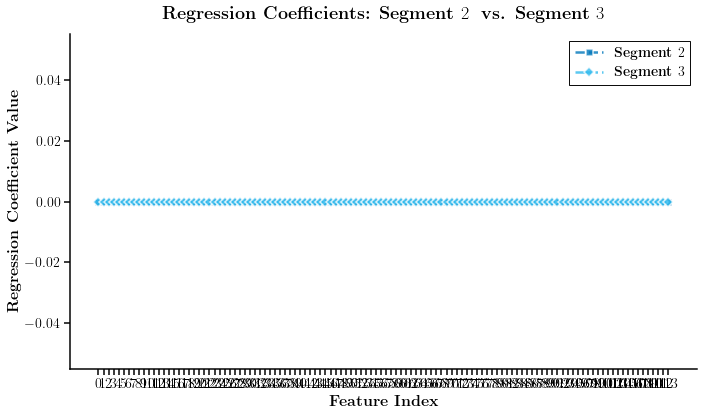

Plot saved as figures/segment_coeffs_seg3_vs_seg4.pdf and figures/segment_coeffs_seg3_vs_seg4.pgf


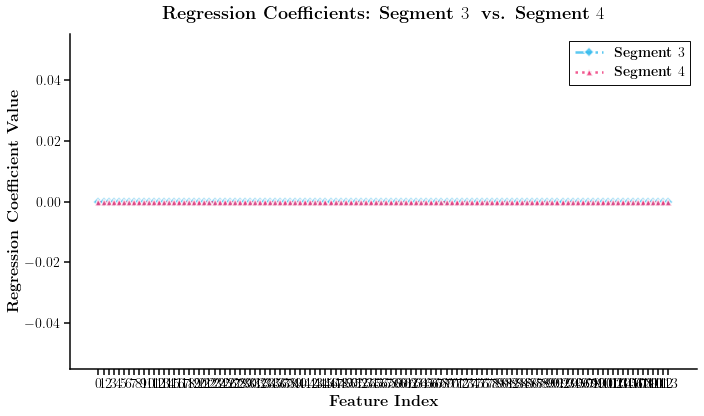

Regression coefficient plotting completed.


In [17]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import gc
import datetime # For potential date handling if needed, though not directly used in this plot
import os # For creating directories

# Assuming jax and scipy are installed and available
import jax.numpy as jnp
import jax
import scipy.optimize

# --- Matplotlib Cleanup and Backend Setting ---
# Close all existing figures first
try:
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib and set backend
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# --- Publication-Ready Matplotlib Parameters ---
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,    # Larger axis labels
    'axes.titlesize': 18,    # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 72,          # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# --- Color Palette ---
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']
PAL = TOL_VIBRANT
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Assume X, y, and cp are preloaded from your environment ---
# For demonstration purposes, I'll define dummy X, y, and cp here.
# In your actual script, these lines should be removed as they are preloaded.
# Example dummy data:
# np.random.seed(42)
# num_points = 200
# p_features = 5
# X = np.random.rand(num_points, p_features)
# y = np.concatenate([
#     X[:50, :] @ np.array([1, 2, 0.5, -1, 0.2]) + np.random.normal(0, 0.1, 50),
#     X[50:100, :] @ np.array([0.5, 1, 2, 0.1, -0.5]) + np.random.normal(0, 0.1, 50),
#     X[100:150, :] @ np.array([2, 0.5, -1, 0.8, 1.5]) + np.random.normal(0, 0.1, 50),
#     X[150:, :] @ np.array([-0.5, 1.5, 0.2, 1, 0.7]) + np.random.normal(0, 0.1, 50)
# ])
# cp = np.array([50, 100, 150])
#
# # Dummy loss function M and its gradient for JAX
# def M(predictions, targets):
#     return jnp.mean((predictions - targets)**2) # Mean Squared Error
#
# # Ensure jax.grad is available
# try:
#     _ = jax.grad(lambda x: x**2) # Test if jax.grad works
# except Exception:
#     print("Warning: jax.grad might not be properly configured or JAX is not installed.")
#     print("Please ensure JAX is installed and correctly set up for gradient computation.")


# --- Segment the data based on the estimated change points, and compute the regression vector for each segment ---
segments = []
η̂ = cp  # Estimated change points
# Ensure η̂ includes the start and end of the data points
η̂_extended = np.concatenate(([0], η̂, [len(y)]))  # Add start and end indices
for i in range(0, len(η̂_extended)-1):
    start = η̂_extended[i]
    end = η̂_extended[i + 1]
    segment_X = X[start:end, :]
    segment_y = y[start:end]
    segments.append((segment_X, segment_y))

# Compute the regression vector for each segment
p = X.shape[1] # Number of features
B̂_segments = np.zeros((p, len(segments))) # Stores regression vectors for each segment

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)
# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

C_best = best_L_tilde[1]  # Assuming best_L_tilde is a tuple (L, C), we take C
print(f"Using C_best: {C_best} for regularization")
l1_reg_best = C_best * lambda_hat
print(f"Computed l1_reg_best: {l1_reg_best}")
P_func = lambda beta: l1_reg_best * jnp.sum(jnp.abs(beta))

# Use enumerate to get both the index (i) and the data (segment)
for i, (segment_X, segment_y) in enumerate(segments):
    if segment_X.shape[0] == 0: # Handle empty segments if any
        print(f"Warning: Segment {i+1} is empty. Skipping regression for this segment.")
        # You might want to assign NaNs or zeros to B̂_segments[:, i] here
        continue

    # sample_weight = np.ones(segment_X.shape[0]) / segment_X.shape[0]  # Uniform weights
    # empirical_risk = lambda β: M((segment_X @ β).flatten(), segment_y.flatten()).sum()
    def empirical_risk(β):
        """
        Computes the empirical risk for the given regression coefficients β.
        This is a wrapper around the loss function M.
        """
        predictions = segment_X @ β
        # Use the loss function M to compute the risk
        return M(predictions.flatten(), segment_y.flatten()).sum()/n + P_func(β)

    # Ensure the initial guess has the correct shape (p,)
    initial_guess = np.zeros(p)

    # Use jax.grad for the Jacobian
    res = scipy.optimize.minimize(empirical_risk, initial_guess, jac=jax.grad(empirical_risk), method='L-BFGS-B')

    # Use the index 'i' from enumerate for correct assignment
    B̂_segments[:, i] = res.x

    # Print the mean and standard deviation of the regression coefficients for this segment
    print(f"Segment {i+1} - Mean: {B̂_segments[:, i].mean()}, Std: {B̂_segments[:, i].std()}")
    # Also print the mean and std of the first 10 coefficients
    print(f"Segment {i+1} - First 10 Coefficients Mean: {B̂_segments[:10, i].mean()}, Std: {B̂_segments[:10, i].std()}")

# --- Plot 1: Regression Coefficients for Each Segment (Publication-Ready) ---
def plot_segment_coefficients(B_segments_data, title_label=''):
    """
    Plots the regression coefficients for each segment in a publication-ready style.

    Args:
        B_segments_data (np.ndarray): A (p, num_segments) array where each column
                                      is the regression vector for a segment.
        title_label (str): Optional label for the plot title.
    """
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))

    num_segments = B_segments_data.shape[1]
    feature_indices = np.arange(B_segments_data.shape[0])

    # Define markers and linestyles to match the number of segments
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]

    for ℓ in range(num_segments):
        # Use colors from PAL, cycle through markers and linestyles
        color = PAL[ℓ % len(PAL)]
        marker = markers[ℓ % len(markers)]
        linestyle = linestyles[ℓ % len(linestyles)]

        ax.plot(feature_indices, B_segments_data[:, ℓ],
                label=r'\textbf{Segment }' + str(ℓ+1),
                marker=marker, ls=linestyle, color=color,
                linewidth=2.5, markersize=7,
                markeredgewidth=1.5, markeredgecolor='white',
                alpha=0.8)

    ax.set_xlabel(r'\textbf{Feature Index}', fontsize=16)
    ax.set_ylabel(r'\textbf{Regression Coefficient Value}', fontsize=16)
    ax.set_title(r'\textbf{Regression Coefficients Across Segments}' + title_label, pad=15)

    # Cleaner axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Set x-ticks to be integer feature indices
    ax.set_xticks(feature_indices)

    ax.legend(loc='best', frameon=True, edgecolor='black', framealpha=0.95, ncol=2)
    fig.tight_layout()

    return fig, ax

# --- Plot 2: Coefficients of Adjacent Segments Against Each Other (Publication-Ready) ---
def plot_adjacent_coefficient_comparison(B_segments_data, title_label=''):
    """
    Plots the regression coefficients of adjacent segments against each other.

    Args:
        B_segments_data (np.ndarray): A (p, num_segments) array where each column
                                      is the regression vector for a segment.
        title_label (str): Optional label for the plot title.
    """
    num_segments = B_segments_data.shape[1]
    if num_segments < 2:
        print("Not enough segments to plot adjacent coefficient comparison (need at least 2).")
        return None, None

    fig, ax = plt.subplots(1, 1, figsize=(8, 8)) # Square plot for 1:1 comparison

    # Define markers and linestyles for different pairs
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']

    for i in range(num_segments - 1):
        segment_1_coeffs = B_segments_data[:, i]
        segment_2_coeffs = B_segments_data[:, i+1]

        color = PAL[i % len(PAL)]
        marker = markers[i % len(markers)]

        ax.scatter(segment_1_coeffs, segment_2_coeffs,
                   label=r'\textbf{Seg. }' + str(i+1) + r' \textbf{vs. Seg. }' + str(i+2),
                   color=color, marker=marker, s=100, # s is marker size
                   edgecolor='black', linewidth=0.8, alpha=0.8)

    # Add a diagonal line (y=x) for reference
    min_val = np.min(B_segments_data)
    max_val = np.max(B_segments_data)
    # Extend the line slightly beyond min/max for better visual
    buffer = (max_val - min_val) * 0.1
    ax.plot([min_val - buffer, max_val + buffer], [min_val - buffer, max_val + buffer],
            color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label=r'\textbf{Diagonal} ($y=x$)', zorder=0)

    ax.set_xlabel(r'\textbf{Coefficient from Segment } $\ell$', fontsize=16)
    ax.set_ylabel(r'\textbf{Coefficient from Segment } $\ell+1$', fontsize=16)
    ax.set_title(r'\textbf{Adjacent Segment Coefficient Comparison}' + title_label, pad=15)

    # Ensure equal aspect ratio for a true 1:1 comparison
    ax.set_aspect('equal', adjustable='box')

    # Cleaner axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    ax.legend(loc='best', frameon=True, edgecolor='black', framealpha=0.95, ncol=1)
    fig.tight_layout()

    return fig, ax

# --- NEW Plot 3: Individual Plots of Adjacent Segment Coefficients ---
def plot_segment_coefficients_pairwise(B_segments_data, title_prefix=''):
    """
    Generates individual publication-ready plots comparing regression coefficients
    of adjacent segments. Each plot shows two adjacent segments.

    Args:
        B_segments_data (np.ndarray): A (p, num_segments) array where each column
                                      is the regression vector for a segment.
        title_prefix (str): Optional prefix for the plot title.
    """
    num_segments = B_segments_data.shape[1]
    feature_indices = np.arange(B_segments_data.shape[0])

    if num_segments < 2:
        print("Not enough segments to plot pairwise coefficient comparison (need at least 2).")
        return

    # Define markers and linestyles to match the number of segments
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]

    for i in range(num_segments - 1):
        fig, ax = plt.subplots(1, 1, figsize=(10, 6))

        # Plot current segment (ℓ)
        color1 = PAL[i % len(PAL)]
        marker1 = markers[i % len(markers)]
        linestyle1 = linestyles[i % len(linestyles)]
        ax.plot(feature_indices, B_segments_data[:, i],
                label=r'\textbf{Segment }' + str(i+1),
                marker=marker1, ls=linestyle1, color=color1,
                linewidth=2.5, markersize=7,
                markeredgewidth=1.5, markeredgecolor='white',
                alpha=0.8)

        # Plot next segment (ℓ+1)
        color2 = PAL[(i + 1) % len(PAL)]
        marker2 = markers[(i + 1) % len(markers)]
        linestyle2 = linestyles[(i + 1) % len(linestyles)]
        ax.plot(feature_indices, B_segments_data[:, i+1],
                label=r'\textbf{Segment }' + str(i+2),
                marker=marker2, ls=linestyle2, color=color2,
                linewidth=2.5, markersize=7,
                markeredgewidth=1.5, markeredgecolor='white',
                alpha=0.8)

        ax.set_xlabel(r'\textbf{Feature Index}', fontsize=16)
        ax.set_ylabel(r'\textbf{Regression Coefficient Value}', fontsize=16)
        ax.set_title(title_prefix + r'\textbf{Segment }' + str(i+1) + r' \textbf{ vs. Segment }' + str(i+2), pad=15)

        # Cleaner axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

        # Set x-ticks to be integer feature indices
        ax.set_xticks(feature_indices)

        ax.legend(loc='best', frameon=True, edgecolor='black', framealpha=0.95, ncol=1)
        fig.tight_layout()

        # Save each individual plot
        filename_pairwise = f'segment_coeffs_seg{i+1}_vs_seg{i+2}'
        fig.savefig(f'figures/{filename_pairwise}.pdf', dpi=300, bbox_inches='tight')
        fig.savefig(f'figures/{filename_pairwise}.pgf', dpi=300, bbox_inches='tight')
        print(f"Plot saved as figures/{filename_pairwise}.pdf and figures/{filename_pairwise}.pgf")
        plt.show(fig) # Show each plot as it's generated

# --- Execute Plotting Functions ---
os.makedirs('figures', exist_ok=True) # Ensure 'figures' directory exists

print("\nCreating publication-ready regression coefficient plots...")

# Plot 1: Regression Coefficients for Each Segment (All on one plot)
fig_coeffs, ax_coeffs = plot_segment_coefficients(B̂_segments, title_label=r' (WERM Estimation)')
if fig_coeffs:
    filename_coeffs = 'segment_regression_coefficients_all' # Renamed for clarity
    fig_coeffs.savefig(f'figures/{filename_coeffs}.pdf', dpi=300, bbox_inches='tight')
    fig_coeffs.savefig(f'figures/{filename_coeffs}.pgf', dpi=300, bbox_inches='tight')
    print(f"Plot saved as figures/{filename_coeffs}.pdf and figures/{filename_coeffs}.pgf")
    plt.show(fig_coeffs)

# Plot 2: Coefficients of Adjacent Segments Against Each Other (Scatter plot)
fig_adjacent, ax_adjacent = plot_adjacent_coefficient_comparison(B̂_segments, title_label=r' (WERM Estimation)')
if fig_adjacent:
    filename_adjacent = 'adjacent_segment_coefficient_comparison'
    fig_adjacent.savefig(f'figures/{filename_adjacent}.pdf', dpi=300, bbox_inches='tight')
    fig_adjacent.savefig(f'figures/{filename_adjacent}.pgf', dpi=300, bbox_inches='tight')
    print(f"Plot saved as figures/{filename_adjacent}.pdf and figures/{filename_adjacent}.pgf")
    plt.show(fig_adjacent)

# Plot 3: Individual Plots of Adjacent Segment Coefficients (New Function)
print("\nCreating individual plots for adjacent segment coefficient comparisons...")
plot_segment_coefficients_pairwise(B̂_segments, title_prefix=r'\textbf{Regression Coefficients: }')

print("Regression coefficient plotting completed.")


# WERM unpenalized

In [4]:
from itertools import product
import jax.numpy as jnp
import WERM.estimators
n, p = X.shape
  
# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)
M_scorer = M

# Huber Loss
def M(u, v, epsilon=1.35):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)

# Absolute value loss
M_scorer = lambda u, v: jnp.abs(u - v)

L=5
delta_fraction = 1/10
Delta_n = lambda n_len: int(n_len * delta_fraction)

cp_list = []
gof_list = []
for L_tilde in range(1, L + 1):
    print(f"Using L_tilde: {L_tilde}")
    cp, gof = WERM.estimators.weighted_erm(X, y, M, L=L_tilde, Delta_n=Delta_n(n), gamma=0.0,
                        brute_force=False, return_gof=True)
    cp_list.append(cp)
    gof_list.append(gof)
    print(f"Estimated change points for L_tilde={L_tilde}: {cp} with gof={gof}")

# C_candidates = np.array([0])
# L_candidates = np.arange(L, L + 1)
# gamma_candidates = list(product(L_candidates, C_candidates))


# num_folds = 2
# best_L_tilde, best_chgpt_est = WERM.estimators.chgpt_k_fold_cv(
#     f=f,
#     X=X,
#     y=y,
#     gamma_candidates=gamma_candidates,
#     M_scorer=M_scorer,
#     P_scorer=None,
#     k=num_folds,
#     n_jobs=1
# )
# print("Best (L, C): ", best_L_tilde)
# print("Estimated changepoints (Full CV): ", best_chgpt_est)

Using L_tilde: 1
\Delta: 4, n: 50, Lmin: 1, Lmax: 1


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Estimated change points for L_tilde=1: [] with gof=135.8414788756241
Using L_tilde: 2
\Delta: 4, n: 50, Lmin: 2, Lmax: 2


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

... (6 outputs left out)

  Tested 772 valid positions
  Best 5 improvements: [(129, Array(82.08864856, dtype=float64), Array(162.18703006, dtype=float64)), (130, Array(82.08133308, dtype=float64), Array(162.19434554, dtype=float64)), (128, Array(82.0255358, dtype=float64), Array(162.25014282, dtype=float64)), (127, Array(81.92091524, dtype=float64), Array(162.35476338, dtype=float64)), (155, Array(81.90845532, dtype=float64), Array(162.3672233, dtype=float64))]
  Tested 619 valid positions
  Best 5 improvements: [(329, Array(34.83779933, dtype=float64), Array(127.34923073, dtype=float64)), (325, Array(34.826035, dtype=float64), Array(127.36099506, dtype=float64)), (326, Array(34.81451691, dtype=float64), Array(127.37251315, dtype=float64)), (335, Array(34.80730109, dtype=float64), Array(127.37972897, dtype=float64)), (327, Array(34.79645171, dtype=float64), Array(127.39057835, dtype=float64))]
  Tested 466 valid positions
  Best 5 improvements: [(654, Array(42.51395128, dtype=float64), Array(84.83527946, dtype

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/20475 [00:00<?, ?it/s]

  Tested 772 valid positions
  Best 5 improvements: [(105, Array(117.92841219, dtype=float64), Array(204.86605229, dtype=float64)), (104, Array(117.91991535, dtype=float64), Array(204.87454913, dtype=float64)), (103, Array(117.8651757, dtype=float64), Array(204.92928878, dtype=float64)), (112, Array(117.81216613, dtype=float64), Array(204.98229836, dtype=float64)), (111, Array(117.77312877, dtype=float64), Array(205.02133571, dtype=float64))]
  Tested 619 valid positions
  Best 5 improvements: [(279, Array(55.63501291, dtype=float64), Array(149.23103937, dtype=float64)), (280, Array(55.60812151, dtype=float64), Array(149.25793077, dtype=float64)), (281, Array(55.52289231, dtype=float64), Array(149.34315998, dtype=float64)), (282, Array(55.48584314, dtype=float64), Array(149.38020915, dtype=float64)), (283, Array(55.46367795, dtype=float64), Array(149.40237434, dtype=float64))]
  Tested 466 valid positions
  Best 5 improvements: [(488, Array(32.0710778, dtype=float64), Array(117.1599615

WERM chpt estimate:  []
Change point dates (ERM):  []
Done optimizing gof erm.


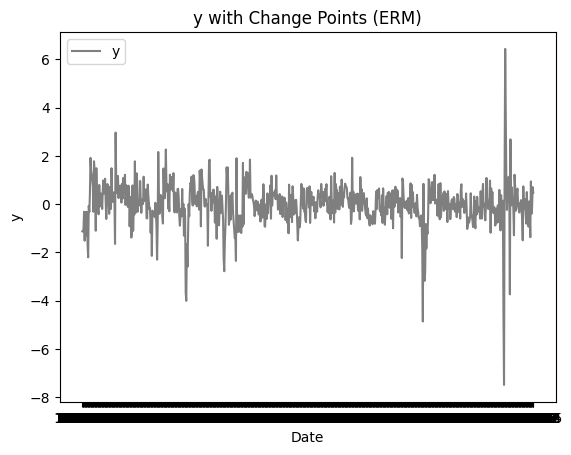

WERM chpt estimate:  [346]
Change point dates (ERM):  ['1988-11']
Done optimizing gof erm.


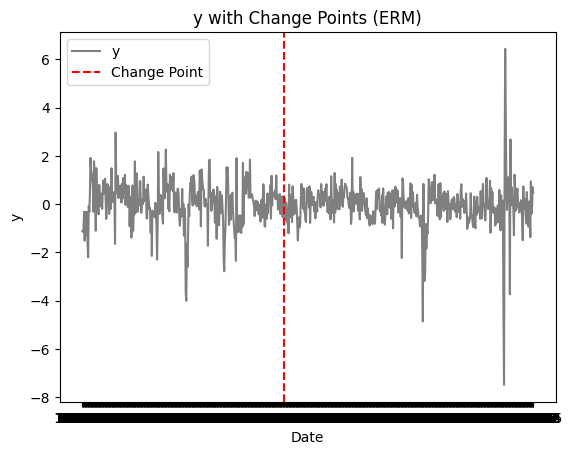

WERM chpt estimate:  [264 584]
Change point dates (ERM):  ['1982-01' '2008-09']
Done optimizing gof erm.


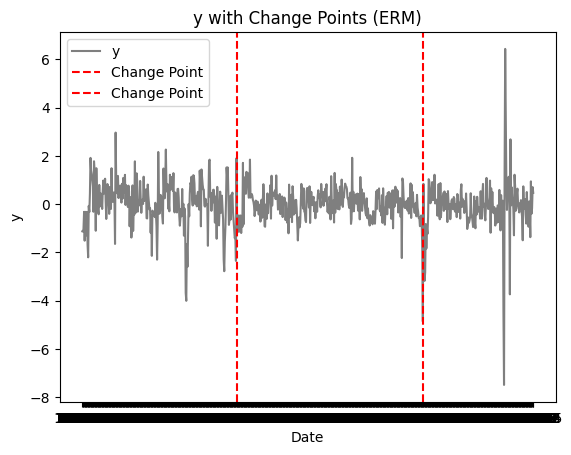

WERM chpt estimate:  [129 329 654]
Change point dates (ERM):  ['1970-10' '1987-06' '2014-07']
Done optimizing gof erm.


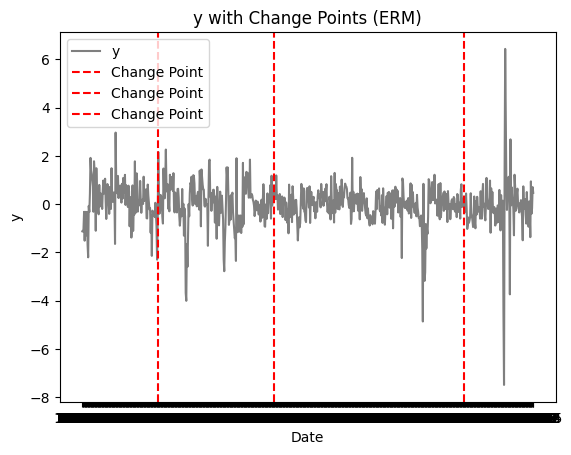

WERM chpt estimate:  [105 279 488 654]
Change point dates (ERM):  ['1968-10' '1983-04' '2000-09' '2014-07']
Done optimizing gof erm.


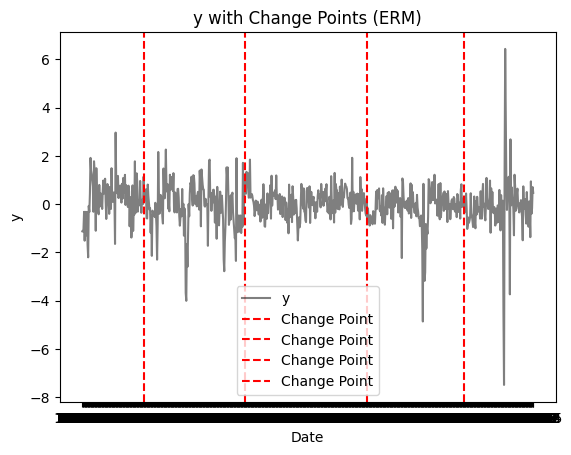

Elbow index: 2, L_tilde: 3, Score: 97.53871144127183


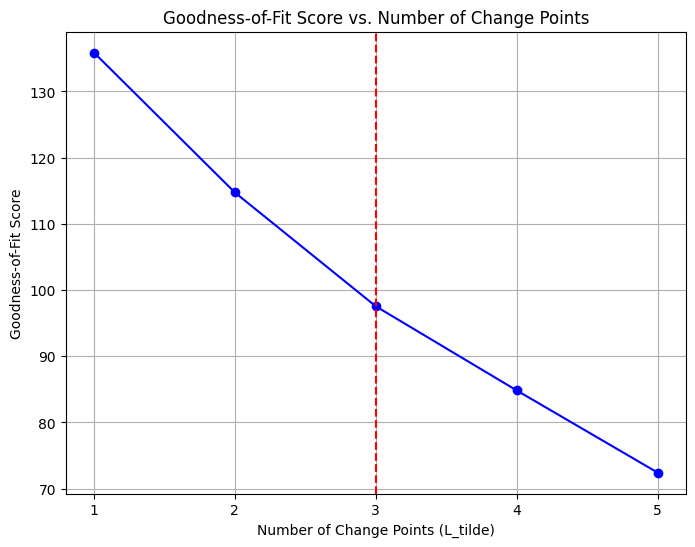

In [6]:
import matplotlib.pyplot as plt
# cp = best_chgpt_est
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
for cp in cp_list:
    print("WERM chpt estimate: ", cp)
    # Print the dates associated with the change points
    chgpt_dates_erm = date[cp]
    print("Change point dates (ERM): ", chgpt_dates_erm)
    print("Done optimizing gof erm.")

    # Plot the y values with the change points as vertical lines
    plt.plot(date, y, label='y', color='black', alpha=0.5)
    plt.title('y with Change Points (ERM)')
    for chgpt in chgpt_dates_erm:
        plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
    plt.xlabel('Date')
    plt.ylabel('y')
    plt.legend()
    plt.show()

def find_elbow(gof_list):
    """
    Identify the elbow index (and score) in a list of goodness‐of‐fit scores
    using the “average of the two connecting slopes” criterion.

    Parameters
    ----------
    gof_list : List[float]
        A sequence of scores (lower is better), ordered by increasing model
        complexity (or number of change‐points).

    Returns
    -------
    elbow_idx : int
        The index of the elbow point in gof_list.
    elbow_score : float
        The score at that index.
    """
    n = len(gof_list)
    if n < 3:
        raise ValueError("Need at least three points to compute an elbow.")
    # Compute the average slopes for points 1 through n-2
    avg_slopes = []
    for i in range(1, n-1):
        left_slope  = gof_list[i]   - gof_list[i-1]
        right_slope = gof_list[i+1] - gof_list[i]
        avg_slopes.append((left_slope + right_slope) / 2.0)

    # Find the first position where the magnitude of the avg slope drops
    # compared to the previous point
    for j in range(1, len(avg_slopes)):
        if abs(avg_slopes[j]) < abs(avg_slopes[j-1]):
            elbow_idx   = j + 1               # shift back to gof_list indexing
            elbow_score = gof_list[elbow_idx]
            return elbow_idx, elbow_score

    # If we never see a drop, fall back to the last point
    return n-1, gof_list[-1]
# Plot the scores, together with the elbow point
plt.figure(figsize=(8, 6))
plt.plot(range(1, L + 1), gof_list, marker='o', linestyle='-', color='blue')
elbow_idx = find_elbow(gof_list)[0]
print(f"Elbow index: {elbow_idx}, L_tilde: {elbow_idx + 1}, Score: {gof_list[elbow_idx]}")
plt.axvline(x=elbow_idx + 1, color='red', linestyle='--', label='Elbow Point')
plt.xticks(range(1, L + 1))
plt.xlabel('Number of Change Points (L_tilde)')
plt.ylabel('Goodness-of-Fit Score')
plt.title('Goodness-of-Fit Score vs. Number of Change Points')
plt.grid(True)
plt.show()


Removing 110 matplotlib modules...
Successfully set backend to: pgf
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Error converting dates to datetime objects: time data '1960-01' does not match format '%Y-%m-%d'
Please ensure your 'date' array contains strings in a consistent format (e.g., 'YYYY-MM-DD').

Creating publication-ready change point plot...
Change point estimates (indices):  [264 584]
Change point dates:  [np.str_('1982-01'), np.str_('2008-09')]
Plot saved as figures/FRED-MD-3-chgpt-unpenalized-.pdf and figures/FRED-MD-3-chgpt-unpenalized-.pgf


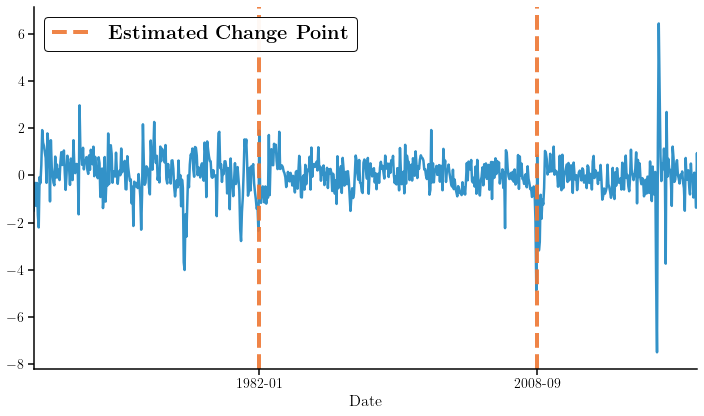

Change point plotting completed.


In [8]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import gc
import datetime # For date conversion
import os # For creating directories

cp=cp_list[elbow_idx]
# --- Matplotlib Cleanup and Backend Setting ---
# Close all existing figures first
try:
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib and set backend
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# --- Publication-Ready Matplotlib Parameters ---
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,    # Larger axis labels
    'axes.titlesize': 18,    # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': False,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 72,          # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# --- Color Palette ---
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']
PAL = TOL_VIBRANT
print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- IMPORTANT: Convert date strings to datetime objects ---
try:
    if isinstance(date[0], (np.str_, str)):
        converted_dates = [datetime.datetime.strptime(str(d), '%Y-%m-%d').date() for d in date]
        date = converted_dates
    else:
        print("Date array already contains datetime objects or an unexpected type. Skipping conversion.")
except Exception as e:
    print(f"Error converting dates to datetime objects: {e}")
    print("Please ensure your 'date' array contains strings in a consistent format (e.g., 'YYYY-MM-DD').")


# --- Publication-Ready Change Point Plotting Function ---
def plot_changepoints_publication(dates, y_values, chgpt_indices, title_label=''):
    """
    Generates a publication-ready plot of a time series with overlaid change points.

    Args:
        dates (list or array-like): The dates corresponding to the time series.
                                    Expected to be datetime.date or datetime.datetime objects.
        y_values (list or array-like): The time series data.
        chgpt_indices (list or array-like): The estimated change point indices.
        title_label (str): An optional label to include in the plot title.
    """
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))

    chgpt_dates_erm = [dates[i] for i in chgpt_indices] # Dates at change points

    print("Change point estimates (indices): ", chgpt_indices)
    print("Change point dates: ", chgpt_dates_erm)

    # Plot the y values with the change points as vertical lines
    ax.plot(dates, y_values, 
            color=PAL[1], alpha=0.8, linewidth=2.5) # Using a color from the palette

    # Add vertical lines for change points
    for i, chgpt_date in enumerate(chgpt_dates_erm):
        # Only label the first change point to avoid duplicate legend entries
        label = r'\textbf{Estimated Change Point}' if i == 0 else ""
        ax.axvline(x=chgpt_date, color=PAL[0], linestyle='--',
                   linewidth=4, label=label, alpha=0.9) # Using another color from the palette

    # ax.set_title(r'\textbf{Time Series with Estimated Change Points}' + title_label, pad=15)
    ax.set_xlabel(r'Date')
    # ax.set_ylabel(r'\textbf{Value of} $\mathbf{y}$')

    # Cleaner axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # --- MODIFICATION: Set xticks only at change point dates ---
    ax.set_xticks(chgpt_dates_erm)
    # ax.set_xticklabels([d.strftime('%Y-%m-%d') for d in chgpt_dates_erm], rotation=30, ha='right')
    ax.set_xlim(dates[5], dates[-5])  # Set x limits to the full date range

    ax.legend(loc='best', frameon=True, edgecolor='black', framealpha=0.95, fancybox=True,
              fontsize=20)
    fig.tight_layout()

    return fig, ax

# --- Execute Plotting ---
print("\nCreating publication-ready change point plot...")
fig_chgpt, ax_chgpt = plot_changepoints_publication(date, y, cp, title_label=r' (ERM Method)')

# --- Save and Show Plot ---
filename_prefix = 'FRED-MD-3-chgpt-unpenalized-'
os.makedirs('figures', exist_ok=True) # Ensure 'figures' directory exists

fig_chgpt.savefig(f'figures/{filename_prefix}.pdf', dpi=300, bbox_inches='tight')
fig_chgpt.savefig(f'figures/{filename_prefix}.pgf', dpi=300, bbox_inches='tight')
print(f"Plot saved as figures/{filename_prefix}.pdf and figures/{filename_prefix}.pgf")

plt.show(fig_chgpt)

print("Change point plotting completed.")

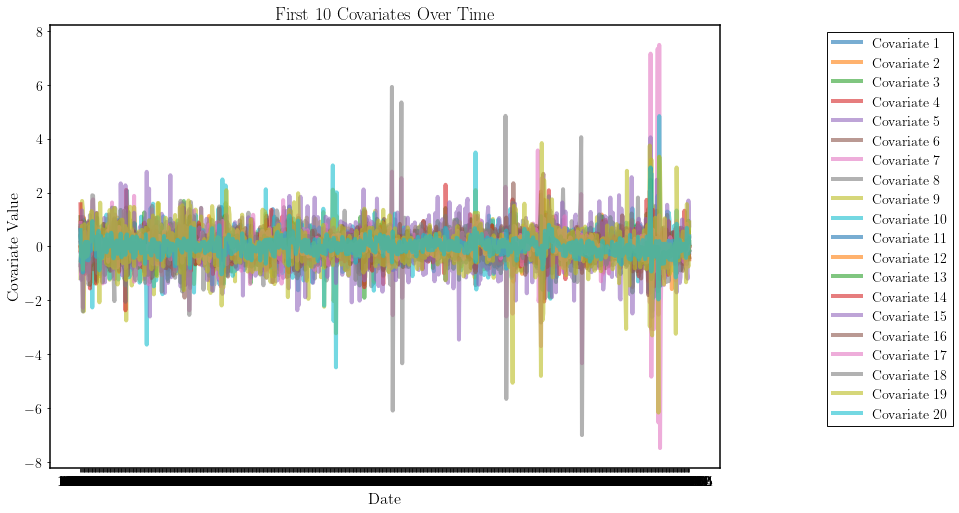

In [165]:
# Plot the first 10 covariates of X over time
num_covariates_to_plot = min(20, X.shape[1])
plt.figure(figsize=(12, 8))
for i in range(num_covariates_to_plot):
    plt.plot(date, X[:, i], label=f'Covariate {i+1}', alpha=0.6)
plt.xlabel('Date')
plt.ylabel('Covariate Value')
plt.title('First 10 Covariates Over Time')
plt.legend(loc='upper left', bbox_to_anchor=(1.15, 1))
plt.show()

## Try with McScan

R McScan estimated change points (0-indexed):  [230 500 722]
WERM chpt estimate:  [230 500 722]
Change point dates (ERM):  ['1979-03' '2001-09' '2020-03']
Done optimizing gof erm.


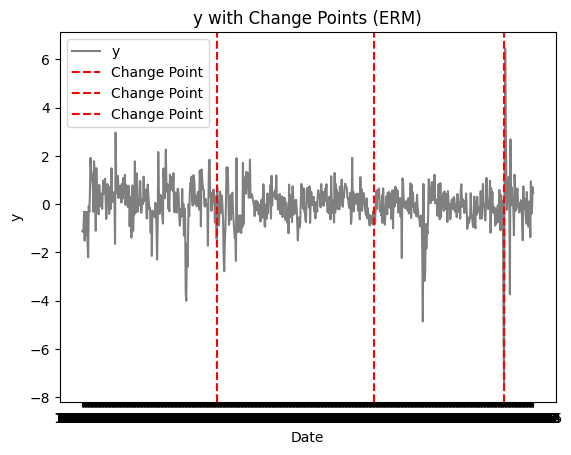

In [16]:
import numpy as np

### Import R interfaces
import rpy2
import rpy2.robjects as ro
## To aid in printing HTML in notebooks
import rpy2.ipython.html
# rpy2.ipython.html.init_printing()
from rpy2.robjects.packages import importr, data

inferchange_package = importr('inferchange') # McScan is a part of inferchange: https://github.com/tobiaskley/inferchange
res = inferchange_package.McScan(X, y, method='auto')
cp = np.array(res[0]).astype(int) - 1
print("R McScan estimated change points (0-indexed): ", cp)

import matplotlib.pyplot as plt
# cp = best_chgpt_est
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", cp)
# Print the dates associated with the change points
chgpt_dates_erm = date[cp]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

# WERM unpenalized on the first 10 features

In [21]:
X_minimal = X[:, :6]

n, p = X_minimal.shape

from itertools import product
import jax.numpy as jnp
import WERM.estimators
  
# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)
M_scorer = M

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)

# Absolute value loss
M_scorer = lambda u, v: jnp.abs(u - v)

L=5
delta_fraction = 1/10
Delta_n = lambda n_len: int(n_len * delta_fraction)

cp_list = []
gof_list = []
for L_tilde in range(1, L + 1):
    print(f"Using L_tilde: {L_tilde}")
    cp, gof = WERM.estimators.weighted_erm(X_minimal, y, M, L=L_tilde, Delta_n=Delta_n(n), gamma=0.0,
                        brute_force=False, return_gof=True)
    cp_list.append(cp)
    gof_list.append(gof)
    print(f"Estimated change points for L_tilde={L_tilde}: {cp} with gof={gof}")

# C_candidates = np.array([0])
# L_candidates = np.arange(L, L + 1)
# gamma_candidates = list(product(L_candidates, C_candidates))


# num_folds = 2
# best_L_tilde, best_chgpt_est = WERM.estimators.chgpt_k_fold_cv(
#     f=f,
#     X=X,
#     y=y,
#     gamma_candidates=gamma_candidates,
#     M_scorer=M_scorer,
#     P_scorer=None,
#     k=num_folds,
#     n_jobs=1
# )
# print("Best (L, C): ", best_L_tilde)
# print("Estimated changepoints (Full CV): ", best_chgpt_est)

Using L_tilde: 1
\Delta: 4, n: 50, Lmin: 1, Lmax: 1


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Estimated change points for L_tilde=1: [] with gof=477.15744424000997
Using L_tilde: 2
\Delta: 4, n: 50, Lmin: 2, Lmax: 2


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

... (6 outputs left out)

  Tested 772 valid positions
  Best 5 improvements: [(182, Array(22.36772154, dtype=float64), Array(478.7911911, dtype=float64)), (209, Array(22.35872076, dtype=float64), Array(478.80019188, dtype=float64)), (181, Array(22.34296652, dtype=float64), Array(478.81594612, dtype=float64)), (184, Array(22.33863462, dtype=float64), Array(478.82027802, dtype=float64)), (208, Array(22.33580201, dtype=float64), Array(478.82311063, dtype=float64))]
  Tested 619 valid positions
  Best 5 improvements: [(727, Array(1.44312025, dtype=float64), Array(477.34807085, dtype=float64)), (728, Array(1.37350819, dtype=float64), Array(477.41768291, dtype=float64)), (730, Array(1.36528081, dtype=float64), Array(477.42591029, dtype=float64)), (729, Array(1.35837478, dtype=float64), Array(477.43281632, dtype=float64)), (732, Array(1.32194691, dtype=float64), Array(477.46924419, dtype=float64))]
  Tested 497 valid positions
  Best 5 improvements: [(288, Array(-5.66008867, dtype=float64), Array(483.00815952, dtype=

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/20475 [00:00<?, ?it/s]

  Tested 772 valid positions
  Best 5 improvements: [(184, Array(31.08774902, dtype=float64), Array(481.04783137, dtype=float64)), (182, Array(31.05615438, dtype=float64), Array(481.07942601, dtype=float64)), (181, Array(31.04579725, dtype=float64), Array(481.08978314, dtype=float64)), (185, Array(30.97405751, dtype=float64), Array(481.16152287, dtype=float64)), (183, Array(30.93313025, dtype=float64), Array(481.20245014, dtype=float64))]
  Tested 619 valid positions
  Best 5 improvements: [(727, Array(6.36177422, dtype=float64), Array(474.68605715, dtype=float64)), (723, Array(6.13376318, dtype=float64), Array(474.91406819, dtype=float64)), (729, Array(5.96827427, dtype=float64), Array(475.0795571, dtype=float64)), (730, Array(5.95235853, dtype=float64), Array(475.09547284, dtype=float64)), (728, Array(5.9521576, dtype=float64), Array(475.09567377, dtype=float64))]
  Tested 497 valid positions
  Best 5 improvements: [(264, Array(-16.80395091, dtype=float64), Array(491.49000806, dtype=

WERM chpt estimate:  []
Change point dates (ERM):  []
Done optimizing gof erm.


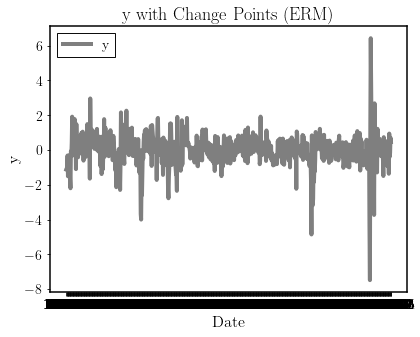

WERM chpt estimate:  [593]
Change point dates (ERM):  ['2009-06']
Done optimizing gof erm.


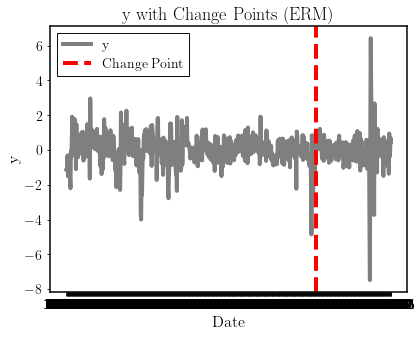

WERM chpt estimate:  [209 593]
Change point dates (ERM):  ['1977-06' '2009-06']
Done optimizing gof erm.


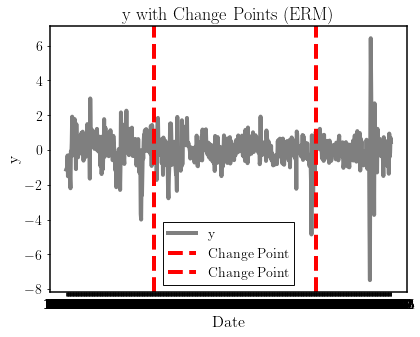

WERM chpt estimate:  [182 288 718]
Change point dates (ERM):  ['1975-03' '1984-01' '2019-11']
Done optimizing gof erm.


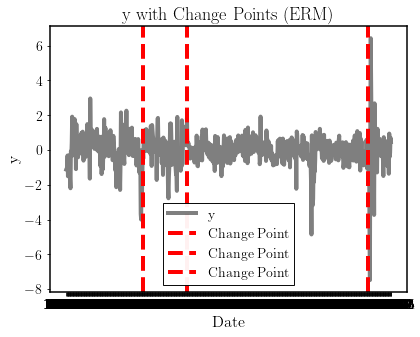

WERM chpt estimate:  [184 264 490 718]
Change point dates (ERM):  ['1975-05' '1982-01' '2000-11' '2019-11']
Done optimizing gof erm.


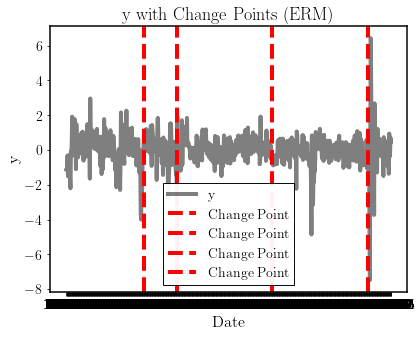

Elbow index: 2, L_tilde: 3, Score: 455.396074870629


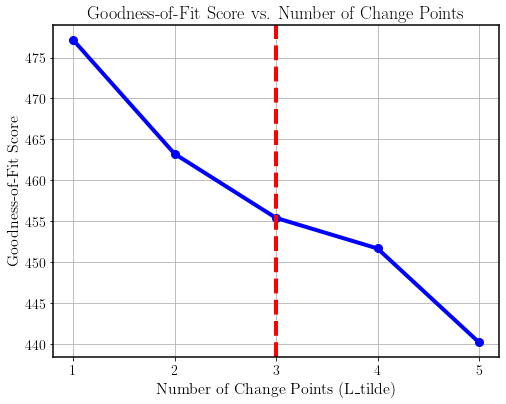

In [22]:
import matplotlib.pyplot as plt
# cp = best_chgpt_est
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
for cp in cp_list:
    print("WERM chpt estimate: ", cp)
    # Print the dates associated with the change points
    chgpt_dates_erm = date[cp]
    print("Change point dates (ERM): ", chgpt_dates_erm)
    print("Done optimizing gof erm.")

    # Plot the y values with the change points as vertical lines
    plt.plot(date, y, label='y', color='black', alpha=0.5)
    plt.title('y with Change Points (ERM)')
    for chgpt in chgpt_dates_erm:
        plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
    plt.xlabel('Date')
    plt.ylabel('y')
    plt.legend()
    plt.show()

def find_elbow(gof_list):
    """
    Identify the elbow index (and score) in a list of goodness‐of‐fit scores
    using the “average of the two connecting slopes” criterion.

    Parameters
    ----------
    gof_list : List[float]
        A sequence of scores (lower is better), ordered by increasing model
        complexity (or number of change‐points).

    Returns
    -------
    elbow_idx : int
        The index of the elbow point in gof_list.
    elbow_score : float
        The score at that index.
    """
    n = len(gof_list)
    if n < 3:
        raise ValueError("Need at least three points to compute an elbow.")
    # Compute the average slopes for points 1 through n-2
    avg_slopes = []
    for i in range(1, n-1):
        left_slope  = gof_list[i]   - gof_list[i-1]
        right_slope = gof_list[i+1] - gof_list[i]
        avg_slopes.append((left_slope + right_slope) / 2.0)

    # Find the first position where the magnitude of the avg slope drops
    # compared to the previous point
    for j in range(1, len(avg_slopes)):
        if abs(avg_slopes[j]) < abs(avg_slopes[j-1]):
            elbow_idx   = j + 1               # shift back to gof_list indexing
            elbow_score = gof_list[elbow_idx]
            return elbow_idx, elbow_score

    # If we never see a drop, fall back to the last point
    return n-1, gof_list[-1]
# Plot the scores, together with the elbow point
plt.figure(figsize=(8, 6))
plt.plot(range(1, L + 1), gof_list, marker='o', linestyle='-', color='blue')
elbow_idx = find_elbow(gof_list)[0]
print(f"Elbow index: {elbow_idx}, L_tilde: {elbow_idx + 1}, Score: {gof_list[elbow_idx]}")
plt.axvline(x=elbow_idx + 1, color='red', linestyle='--', label='Elbow Point')
plt.xticks(range(1, L + 1))
plt.xlabel('Number of Change Points (L_tilde)')
plt.ylabel('Goodness-of-Fit Score')
plt.title('Goodness-of-Fit Score vs. Number of Change Points')
plt.grid(True)
plt.show()
